# SHAP: ¿por qué el modelo ha dicho eso?

Módulo 5072 · SAA · RA3 y RA6 · 40 minutos

Tenemos un modelo que tasa casas. Le damos una casa y dice: **745.100 $**.

El dueño pregunta: *«¿Y por qué tanto?»*

Si solo podemos contestar «porque lo dice el modelo», no sirve. **SHAP sirve para contestar a esa pregunta**: dice qué características de la casa han subido el precio, cuáles lo han bajado y cuánto.

## ¿Para qué sirve SHAP?

1. **Explicar una predicción concreta.** «A su casa le ponemos este precio sobre todo por la zona y por los metros».
2. **Comprobar que el modelo tiene sentido.** Si el modelo sube el precio por algo absurdo (el número de identificador, por ejemplo), hay un problema.
3. **Defender el modelo en el Reto Final.** Cuando te pregunten «¿por qué tu modelo decide esto?», enseñas el gráfico y lo explicas.

Sirve igual para tasar casas, para un modelo de fraude («¿por qué marca esta compra como sospechosa?») o de abandono («¿por qué cree que este cliente se va?»).

## La idea: como un ticket de compra

SHAP explica una predicción como un ticket:

| Concepto | Importe |
|---|---|
| Precio de partida (una casa normal) | 537.800 $ |
| Está en zona cara | **+ 139.000 $** |
| Tiene 269 m² | **+ 125.600 $** |
| Es de 1977 (bastante antigua) | **− 32.400 $** |
| No tiene vistas | **− 16.500 $** |
| El resto de cosas juntas | **− 8.400 $** |
| **Precio que dice el modelo** | **745.100 $** |

Estos son los números reales de una casa de nuestro conjunto de test.

Solo hay que entender tres cosas:
- **Precio de partida:** lo que el modelo diría para una casa normal (el precio medio).
- **Cada característica suma o resta.** Ese número es su **valor SHAP**.
- **Todo sumado da el precio del modelo.** Siempre cuadra.

### Preguntas sobre el ticket

1. ¿Cuánto vale una casa normal para el modelo?
2. ¿Cuántas filas suman (+) y cuántas restan (−)?
3. ¿Qué es lo que más encarece esta casa?

<details><summary>Respuestas</summary>

**1. 537.800 $.** Es la primera fila, el precio de partida. Todas las casas empiezan ahí. Luego cada característica lo mueve arriba o abajo.

**2. Suman 2 y restan 3.** Suman la zona y los metros. Restan el año, las vistas y «el resto». Una casa puede tener cosas buenas y malas a la vez, igual que en la vida real.

**3. La zona: +139.000 $.** Es el número positivo más grande del ticket. Los metros van casi empatados (+125.600 $).

</details>

## Paso 1 · Preparar el modelo

Esta celda carga las casas y entrena un modelo. Usamos solo 8 columnas con nombres en castellano para que los gráficos se lean bien. Ejecútala sin más.

Si es la primera vez, instala SHAP antes: `!pip install shap`

In [1]:
import pandas as pd
import shap
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

df = pd.read_csv('kc_house_data.csv')

# Nos quedamos con 8 características fáciles de entender
casas = pd.DataFrame({
    'metros':            (df['sqft_living'] * 0.0929).round(),  # pies² -> m²
    'calidad':           df['grade'],        # nota de 1 a 13
    'habitaciones':      df['bedrooms'],
    'banos':             df['bathrooms'],
    'vistas':            df['view'],         # 0 = sin vistas, 4 = muy buenas
    'frente_al_agua':    df['waterfront'],   # 1 = sí, 0 = no
    'anio':              df['yr_built'],     # año de construcción
    'latitud':           df['lat'],          # la zona: más al norte, más caro
})
precio = df['price'] / 1000   # en miles de dólares: los gráficos se leen mejor

X_train, X_test, y_train, y_test = train_test_split(casas, precio, test_size=0.2, random_state=42)

modelo = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
modelo.fit(X_train, y_train)
print('Modelo entrenado')

c:\Users\Usuario\anaconda3\envs\Tartanga2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo entrenado


## Paso 2 · Calcular los valores SHAP

Dos líneas. Explicamos 200 casas del test, que son casas que el modelo **no ha visto** al entrenar.

In [2]:
explicador = shap.TreeExplainer(modelo)   # preparamos el explicador
valores = explicador(X_test.iloc[:200])    # calcula cuánto suma o resta cada característica en cada casa

### ¿De dónde sale el precio de partida?

Es **la media de lo que el modelo predice para las casas de entrenamiento**.

Ejemplo con 4 casas. El modelo dice 300, 500, 600 y 750 mil $. La media es (300 + 500 + 600 + 750) / 4 = **537,5 mil $**. Ese sería el precio de partida: lo que el modelo diría para una casa normal, de la que no sabe nada.

En nuestro notebook se hace lo mismo con las 17.290 casas de train. Compruébalo:

In [ ]:
print('Precio de partida de SHAP:        ', valores.base_values[0])
print('Media de lo que predice el modelo:', modelo.predict(X_train).mean())
print('Media de los precios reales:      ', y_train.mean())

**Contesta:** ¿Los tres números se parecen? Entonces, ¿qué es el precio de partida?

<details><summary>Respuesta</summary>

Sí: los tres salen en torno a **537,76**. Los dos primeros son el mismo número (solo cambian los últimos decimales por redondeo), porque el precio de partida **es** la media de lo que predice el modelo. El tercero, la media de los precios reales, sale casi igual, porque un modelo bien entrenado acierta de media.

Por eso se puede decir «el precio de partida es el precio medio». La definición exacta es la media de lo que **predice el modelo**: SHAP explica al modelo, así que parte de lo que dice el modelo.

</details>

## Paso 3 · Explicar una casa

El gráfico se llama **cascada** (`waterfall`). Se lee de abajo arriba, como el ticket:

- **Todo está en miles de dólares:** `+139.03` son 139.030 $.
- **Abajo** (`E[f(x)]`): el precio de partida, unos 538 mil $.
- **Barras rojas:** suben el precio.
- **Barras azules:** lo bajan.
- **Arriba** (`f(x)`): el precio que dice el modelo para esta casa.
- **A la izquierda** de cada barra: cómo es esta casa (por ejemplo `269 = metros`).

Precio real de la casa: 865.0 mil $


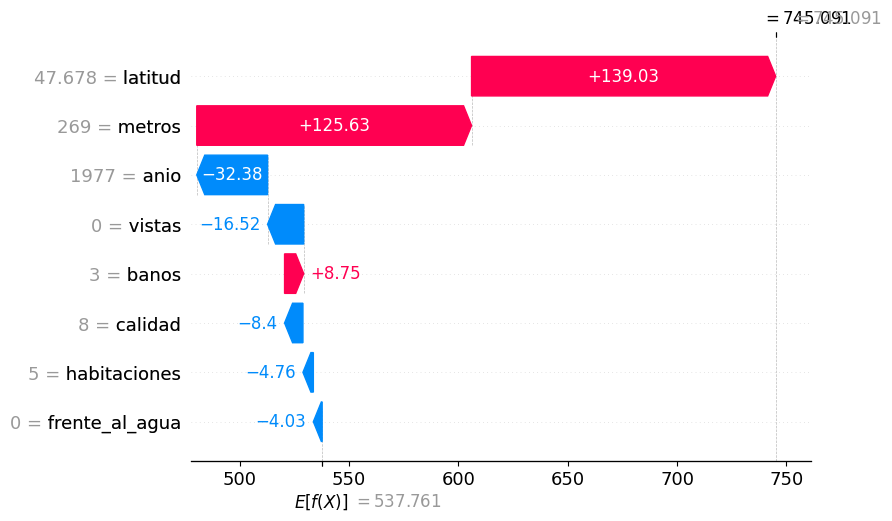

In [3]:
print('Precio real de la casa:', y_test.iloc[1], 'mil $')
shap.plots.waterfall(valores[1])

### Comprobamos la suma

Empezamos en el precio de partida y vamos sumando las barras rojas y restando las azules, de abajo arriba. Todo en miles de dólares.

| Característica | Operación | Va quedando |
|---|---|---|
| Precio de partida, `E[f(X)]` | | 537,76 |
| `frente_al_agua` | − 4,03 | 533,73 |
| `habitaciones` | − 4,76 | 528,97 |
| `calidad` | − 8,40 | 520,57 |
| `banos` | + 8,75 | 529,32 |
| `vistas` | − 16,52 | 512,80 |
| `anio` | − 32,38 | 480,42 |
| `metros` | + 125,63 | 606,05 |
| `latitud` | + 139,03 | **745,08** |

Arriba del gráfico, `f(x)` vale **745,09**. La diferencia de 0,01 se debe a que el gráfico redondea a dos decimales.

- Cada barra empieza donde acabó la anterior.
- El orden no cambia el resultado. El gráfico pone arriba las barras más grandes para que se vea rápido qué influye más.
- Arriba a la derecha los números del gráfico aparecen montados. Es un fallo de dibujo de SHAP: el valor es 745,09.

### Preguntas sobre esta casa

1. ¿De qué color es la barra de `metros`? ¿Sube o baja el precio?
2. ¿Qué barra es la más larga de todas?
3. ¿Qué barra azul es la más larga?
4. Mira arriba del todo, `f(x)`. ¿Cuánto dice el modelo? ¿Y cuánto costó de verdad (el número que ha salido con `print`)?

<details><summary>Respuestas</summary>

**1. Roja, así que sube el precio.** La regla es siempre la misma: rojo suma, azul resta. Los metros suman 125.630 $ (en el gráfico, `+125.63`). La casa tiene 269 m², más que una casa normal, y eso la encarece.

**2. `latitud`, con +139.03.** La barra más larga es la que más mueve el precio. Aquí manda la zona: la casa está en el norte, que es la parte cara.

**3. `anio`, con −32.38.** La casa es de 1977. Para el modelo, una casa antigua vale un poco menos, y le quita 32.380 $.

**4. El modelo dice 745 mil**  y la casa vale 865 mil.  El modelo se ha quedado corto por 120.000 $. SHAP no arregla ese error: solo explica cómo ha llegado el modelo a su número. Si el modelo se equivoca, SHAP explica una predicción equivocada.

</details>

## Paso 4 · Otra casa: la misma característica puede restar

Ahora una casa más barata. Fíjate en qué pasa con la `latitud`.

Precio real de la casa: 365.0 mil $


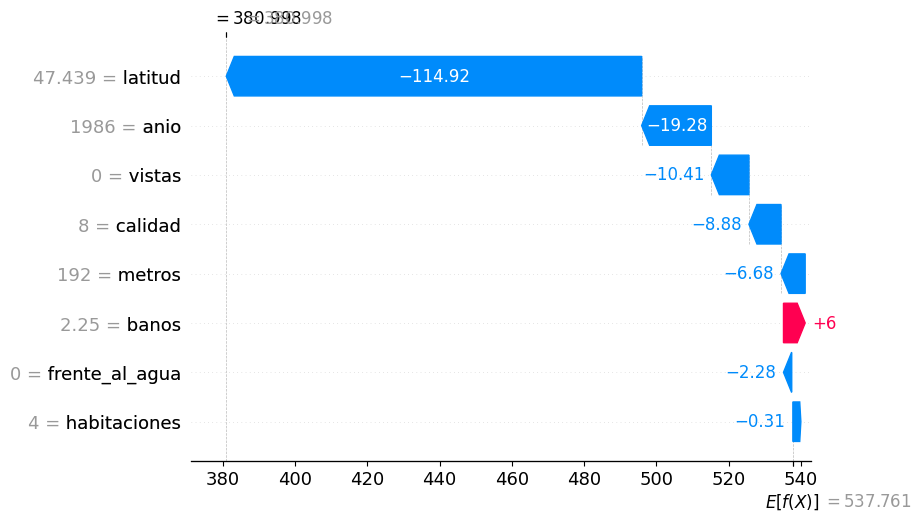

In [4]:
print('Precio real de la casa:', y_test.iloc[0], 'mil $')
shap.plots.waterfall(valores[0])

### Preguntas sobre esta casa

1. ¿De qué color es ahora la barra de `latitud`?
2. Entonces, ¿la zona sube o baja el precio de esta casa? ¿Cuánto?
3. ¿Cuántas barras rojas hay?
4. En la casa anterior la `latitud` sumaba y aquí resta. ¿Por qué? Pista: mira el número que hay a la izquierda de `latitud` en los dos gráficos.

<details><summary>Respuestas</summary>

**1. Azul.**

**2. Lo baja, y mucho: 114.920 $** (en el gráfico, `−114.92`). Es la barra más larga, así que es lo que más explica que esta casa sea barata.

**3. Solo una: `banos`.** Casi todo resta. Por eso el modelo acaba en 381 mil $, muy por debajo de los 538 mil $ de partida. Esta vez el modelo se acerca mucho al precio real (365 mil $).

**4. Porque cada casa está en un sitio distinto.** La casa anterior tenía latitud 47.678 (norte, zona cara). Esta tiene 47.439 (más al sur, zona más barata). La columna es la misma, pero el valor de cada casa es diferente, y por eso empuja hacia un lado o hacia el otro.

Esto es lo más importante del ejercicio: **SHAP explica cada casa por separado.** Una característica no es «buena» o «mala» siempre; depende del valor que tenga esa casa.

</details>

## Paso 5 · Mirando todas las casas a la vez

El gráfico de barras hace la media de las 200 casas. Responde a: **¿qué características mueven más el precio en general?**

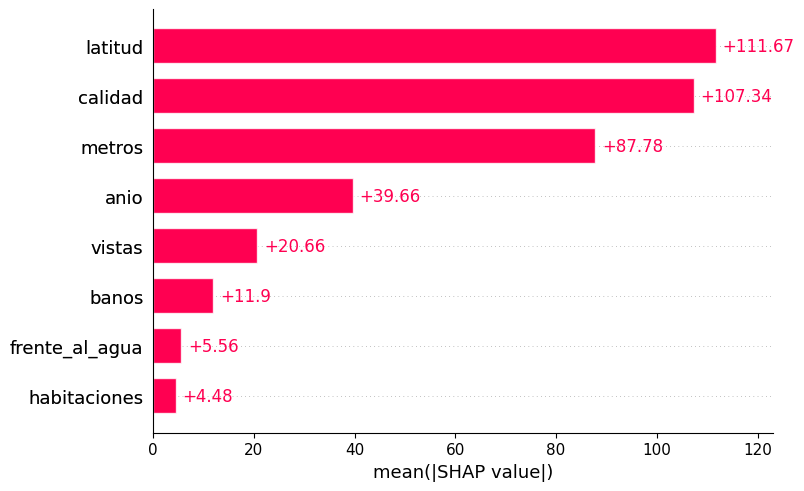

In [5]:
shap.plots.bar(valores)

### Preguntas sobre el gráfico de barras

1. ¿Qué barra es la más larga?
2. ¿Qué tres características están arriba?
3. ¿Cuál está abajo del todo?
4. ¿Te parece lógico? ¿Qué mirarías tú para saber si una casa es cara?

<details><summary>Respuestas</summary>

**1. `latitud`, la zona.**

**2. Zona, calidad y metros.** Están casi empatadas. Son las que más mueven el precio cuando miramos las 200 casas juntas.

**3. `habitaciones`.** Puede sorprender, pero tiene explicación: el modelo ya sabe lo grande que es la casa por los `metros`. Saber además cuántas habitaciones tiene le aporta muy poco.

**4. Sí.** Cualquier persona que busca piso mira primero dónde está, cuántos metros tiene y en qué estado está. El modelo ha aprendido lo mismo a partir de los datos. Si arriba saliera algo sin sentido, tendríamos que revisar el modelo.

**Diferencia con la cascada:** la cascada explica **una** casa. Las barras hacen la media de **todas**. Las barras no dicen si la zona sube o baja el precio; solo dicen que es lo que más influye.

</details>

## Cuidado con dos cosas

- **SHAP explica el modelo, no la realidad.** Si el modelo se equivoca, SHAP explica el error igual de tranquilo.
- **SHAP no demuestra causas.** Que la zona sume 139.000 $ no significa que mudar la casa la haría valer eso. Es lo que el modelo ha aprendido de los datos.

## ¿Lo has entendido? Verdadero o falso

1. Las barras rojas suben el precio.
2. SHAP corrige los errores del modelo.
3. Una misma característica puede subir el precio en una casa y bajarlo en otra.
4. Si sumas el precio de partida y todas las barras, sale el precio que dice el modelo.
5. Si la zona suma 139.000 $, mover la casa a esa zona la haría valer 139.000 $ más.

<details><summary>Respuestas</summary>

**1. Verdadero.** Rojo suma, azul resta.

**2. Falso.** SHAP no cambia la predicción. Solo la explica.

**3. Verdadero.** Lo has visto con la `latitud`: sumaba en la casa del norte y restaba en la del sur.

**4. Verdadero.** Siempre cuadra. Es lo que hace útil a SHAP: reparte la predicción completa entre las características.

**5. Falso.** SHAP dice cómo ha calculado el modelo, no lo que pasaría en la vida real. Que dos cosas vayan juntas en los datos no significa que una cause la otra.

</details>

---
# Para tu Reto Final

**1. Copia estas líneas** después de elegir tu modelo (funciona con árbol de decisión, Random Forest o XGBoost):

```python
import shap
explicador = shap.TreeExplainer(modelo)
valores = explicador(X_val.iloc[:200])   # datos de validación, NO de test

shap.plots.bar(valores)            # qué pesa más en general
shap.plots.waterfall(valores[0])   # explicación de un caso
```

**¿Por qué con validación y no con test?** En el reto el test se usa una sola vez, al final, en la app de Streamlit. SHAP forma parte de elegir y valorar el modelo, y eso se hace con validación. Si miras el test antes, ya no es un examen sorpresa. En este ejercicio hemos usado `X_test` porque no había que elegir ningún modelo.

**¿Y si usas validación cruzada y no tienes un `X_val`?** Coge 200 filas al azar de `X_train`:

```python
X_shap = X_train.sample(200, random_state=42)   # 200 filas al azar de train
valores = explicador(X_shap)
```

Con `GridSearchCV`, la validación se hace dentro de `X_train`, así que no hay un `X_val` aparte. Usar train para SHAP está bien: lo que queremos es ver en qué se fija el modelo, no medir si acierta. Lo que nunca se usa es `X_test`.
